# ET heatmaps with different variance metrics

In [1]:
from pathlib import Path
from datetime import datetime

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

import etunc.config as cfg
from etunc.load.cmip import group_model_variants
from etunc.plotting import set_edge_ticks

In [2]:
def finish(fig, fout, to_save=True):
    tnow = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    fig.suptitle(f"{'climatological ET' if ET_CLIM else 'gridcell-year ET'} - variance-metric-plots.ipynb - {tnow}", x=0.5, ha="center", fontsize=10)
    if to_save:
        fout.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(fout, dpi=cfg.DPI, bbox_inches="tight")

## Load results

In [ ]:
FAMILIES = list(cfg.FAMILIES) + ["plumber"]
ET_CLIM = False
N_BIN = 15
PERIOD = "200101-201412"
BINS = cfg.bins_tag(N_BIN, N_BIN)
TAG = f"qbin_pooled_all.{BINS}.1deg.{PERIOD}"

def qbin_dir(root, fam):
    """Folder of the binned statistics or figures of a family: <root>/<family>/qbin/<period>/<bins>/."""
    return cfg.output_dir(root, fam, "qbin", PERIOD, BINS)


la_mem = {}
pool_all = {}
n_mem = {}
rho_mem = {}
sigma_mem = {}
mu_mem = {}
cv_mem = {}

for fam in FAMILIES:
    if fam != "plumber":
        la_mem[fam] = xr.open_dataset(qbin_dir(cfg.PROC_ROOT, fam) / f"{fam}.land_area.{TAG}.nc")
    
    pool_all[fam] = xr.open_dataset(qbin_dir(cfg.PROC_ROOT, fam) / f"{fam}.et{'_clim' if ET_CLIM else ''}.{TAG}.nc")

    if fam == "plumber":
        pool_all[fam] = pool_all[fam].rename({"lai_pr_rn": "member"})

    et_mean = pool_all[fam].et.sel(stats="mean")
    n_mem[fam] =  pool_all[fam].et.sel(stats="count").sum(dim="member")
    rho_mem[fam] = (n_mem[fam] / n_mem[fam].sum()).where(~np.isnan(n_mem[fam]))
    if fam == "cmip":
        # One value per modeling group: average the members of each model, then the models of each group,
        # and take the mean and std across the group means
        model_mean = et_mean.groupby("source").mean()
        group_of = {sid: grp for grp, sids in group_model_variants(model_mean.source.values).items() for sid in sids}
        model_mean = model_mean.assign_coords(group=("source", [group_of[s] for s in model_mean.source.values]))
        group_mean = model_mean.groupby("group").mean()
        sigma_mem[fam] = group_mean.std(dim="group")
        mu_mem[fam] = group_mean.mean(dim="group")
    else:
        sigma_mem[fam] = et_mean.std(dim="member")
        mu_mem[fam] = et_mean.mean(dim="member")
    cv_mem[fam] = sigma_mem[fam] / mu_mem[fam]

r_cmip_obs = sigma_mem["cmip"] / sigma_mem["obs"]
r_fppe_obs = sigma_mem["fppe"] / sigma_mem["obs"]
r_lens_obs = sigma_mem["lens"] / sigma_mem["obs"]

## Summary plots

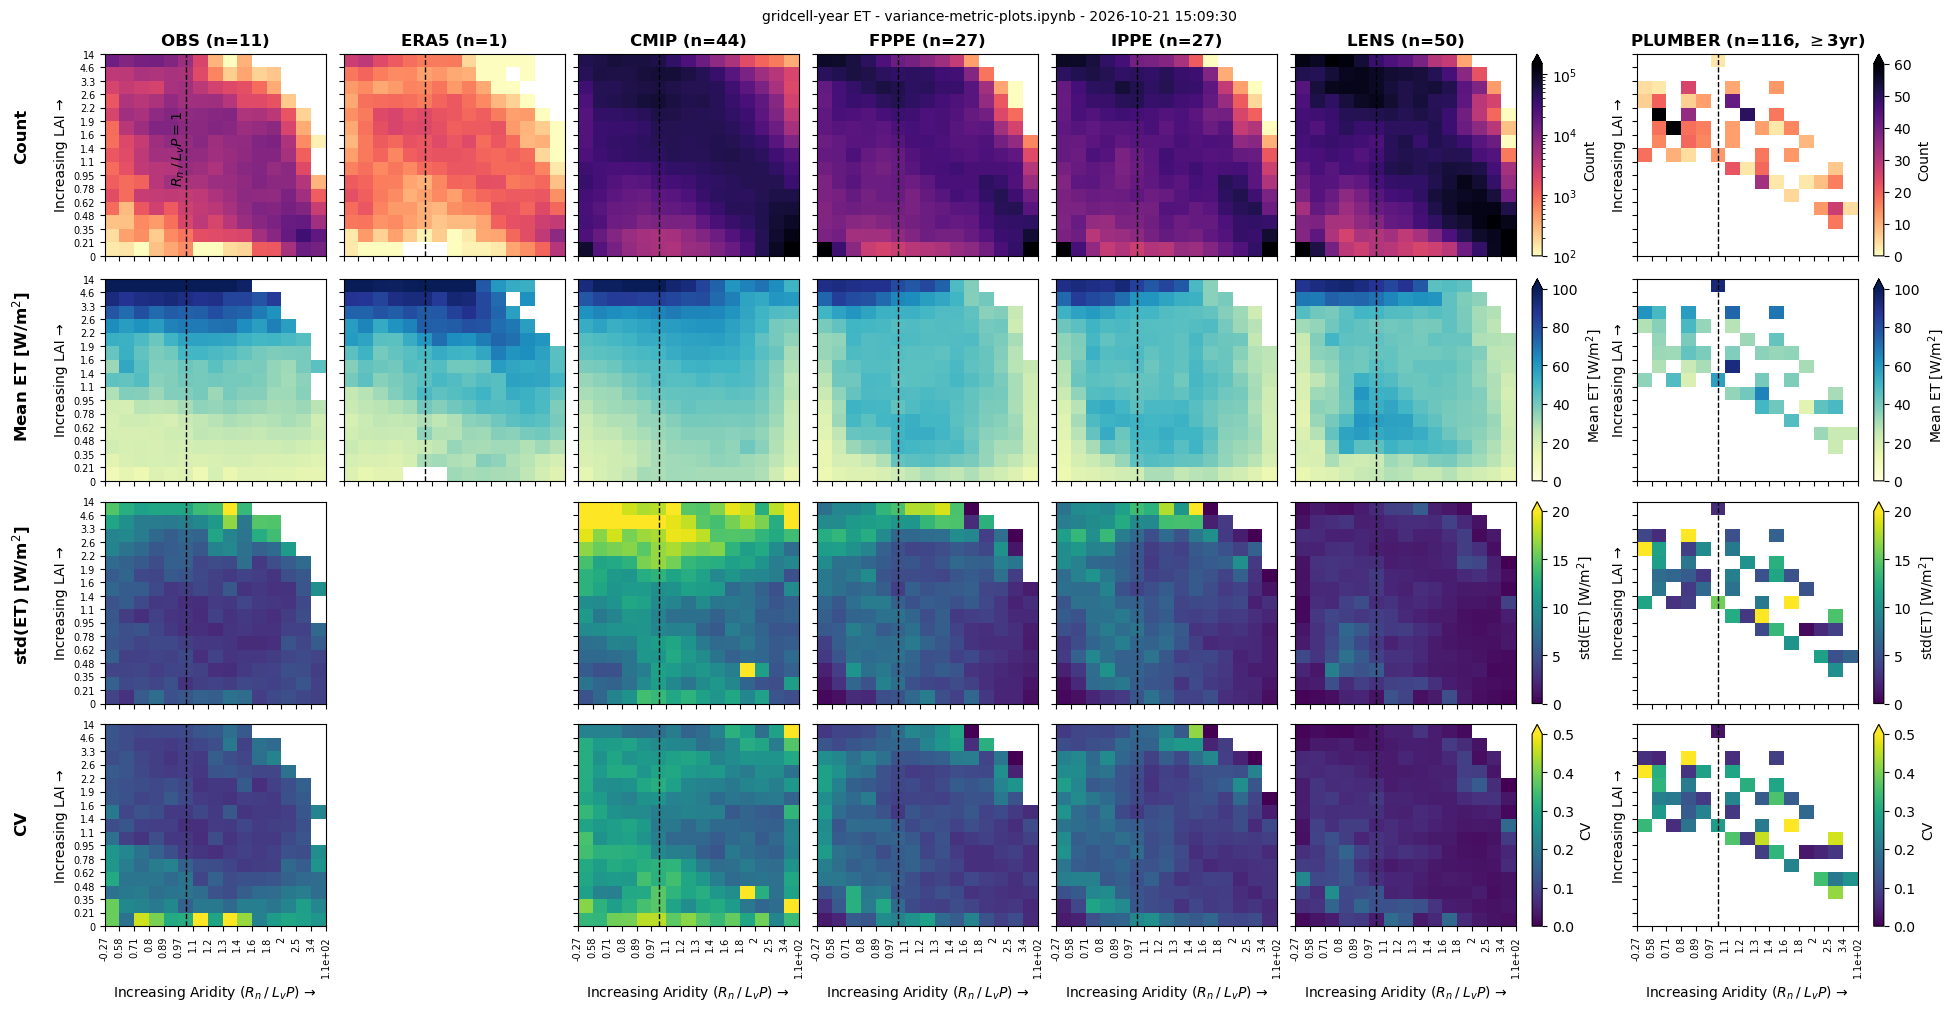

In [4]:
fig, axes = plt.subplots(4, len(FAMILIES), sharex=True, sharey=True, figsize=(19, 10), layout="constrained")
axs = axes.ravel()

vlims = [
    (1e1, 1.5e4) if ET_CLIM else (1e2, 1.5e5),
    (0, 100),
    (0, 20),
    (0, 0.5),
]
cmaps = [
    "magma_r", "YlGnBu", "viridis", "viridis",
]
cv_thresh = 1.0
cv_hatch = "///"

plum_vlims = [
    (0, 15) if ET_CLIM else (0, 60),
    vlims[1],
    vlims[2],
    vlims[3],
]


## GRIDDED PRODUCTS
row_labels = ["Count", "Mean ET [W/m$^2$]", "std(ET) [W/m$^2$]", "CV"]
for i, (label, d) in enumerate(zip(row_labels, [n_mem, mu_mem, sigma_mem, cv_mem])):
    for j, fam in enumerate(cfg.FAMILIES):
        if i == 0:
            norm = mcolors.LogNorm()
        else:
            norm = None
        mappable = d[fam].plot(
            ax=axes[i, j],
            cmap=cmaps[i],
            vmin=vlims[i][0],
            vmax=vlims[i][1],
            add_labels=False,
            add_colorbar=False,
            norm=norm,
        )

        if i == 3:
            axes[i, j].pcolor(
                d[fam].x_bin,
                d[fam].y_bin,
                d[fam].where(d[fam] > cv_thresh),
                facecolor="none", edgecolor="white", hatch=cv_hatch, linewidth=0,
            )

    cb = fig.colorbar(mappable, ax=axes[i, -2], label=label, pad=0.05, extend="max")
    if i == 3:
        cb.ax.axhline(cv_thresh, lw=2, c="white")
        cb.ax.axhspan(
            cv_thresh,
            vlims[i][1],
            facecolor="none", edgecolor="white",
            hatch=cv_hatch, linewidth=0,
        )
        


## PLUMBER
for i, (label, d) in enumerate(zip(
        row_labels,
        [
            pool_all["plumber"].sel(stats="count").where(pool_all["plumber"].sel(stats="count") > 0),
            pool_all["plumber"].sel(stats="mean"),
            np.sqrt(pool_all["plumber"].sel(stats="var_pop")),
            np.sqrt(pool_all["plumber"].sel(stats="var_pop")) / pool_all["plumber"].sel(stats="mean"),
            cv_mem["plumber"],
        ]
    )):
    mappable = d.et.plot(
        ax=axes[i, -1],
        cmap=cmaps[i],
        vmin=plum_vlims[i][0],
        vmax=plum_vlims[i][1],
        add_labels=False,
        add_colorbar=False,
        # cbar_kwargs={"label": label}
    )
    cb = fig.colorbar(mappable, ax=axes[i, -1], label=label, pad=0.05, extend="max")
    if i == 3:
        axes[i, -1].pcolor(
            d.et.x_bin,
            d.et.y_bin,
            d.et.isel(member=0).where(d.et.isel(member=0) > cv_thresh),
            facecolor="none", edgecolor="white", hatch=cv_hatch, linewidth=0,
        )
        cb.ax.axhline(cv_thresh, lw=2, c="white")
        cb.ax.axhspan(
            cv_thresh,
            plum_vlims[i][1],
            facecolor="none", edgecolor="white",
            hatch=cv_hatch, linewidth=0,
        )
    axes[i, -1].set_ylabel("Increasing LAI →")


## FORMATTING + LABELS
for i, label in enumerate(row_labels):
    for j, fam in enumerate(FAMILIES):
        set_edge_ticks(axes[i, j], pool_all[fam], "{:.2g}")

        budyko_one = pool_all[fam].x_bin.sel(x_bin_center=1, method="nearest")
        axes[i, j].axvline(budyko_one, ls="--", c="k", lw=1)
        if (i == 0) and (j == 0):
            axes[i, j].text(
                budyko_one - 0.5, cfg.N_YBINS / 2, "$R_n \\: / \\: L_v P = 1$",
                ha="center", va="center", rotation=90,
                color="k", fontsize=10
            )

        if (i == 0) and (fam != "plumber"):
            axes[i, j].set_title(f"{fam.upper()} (n={len(pool_all[fam].member):d})", fontsize=12, fontweight="bold")
        if (i == 0) and (fam == "plumber"):
            axes[i, j].set_title(f"{fam.upper()} (n={pool_all[fam].et.attrs['n_towers']:d}, $\\geq$3yr)", fontsize=12, fontweight="bold")
        if i == 3:
            axes[i, j].set_xlabel("Increasing Aridity ($R_n \\: / \\: L_v P$) →")
        if j == 0:
            axes[i, j].set_ylabel("Increasing LAI →")

fig.canvas.draw()
for i, label in enumerate(row_labels):
    row_center = axes[i, 0].get_position().y0 + axes[i, 0].get_position().height / 2
    fig.text(-0.015, row_center, label, va="center", ha="center", fontsize=12, fontweight="bold", rotation=90)

axes[2, 1].remove()
axes[3, 1].remove()


fout = qbin_dir(cfg.FIG_ROOT, "all") / f"all.et{'_clim' if ET_CLIM else ''}.{TAG}.summary.png"
finish(fig, fout)

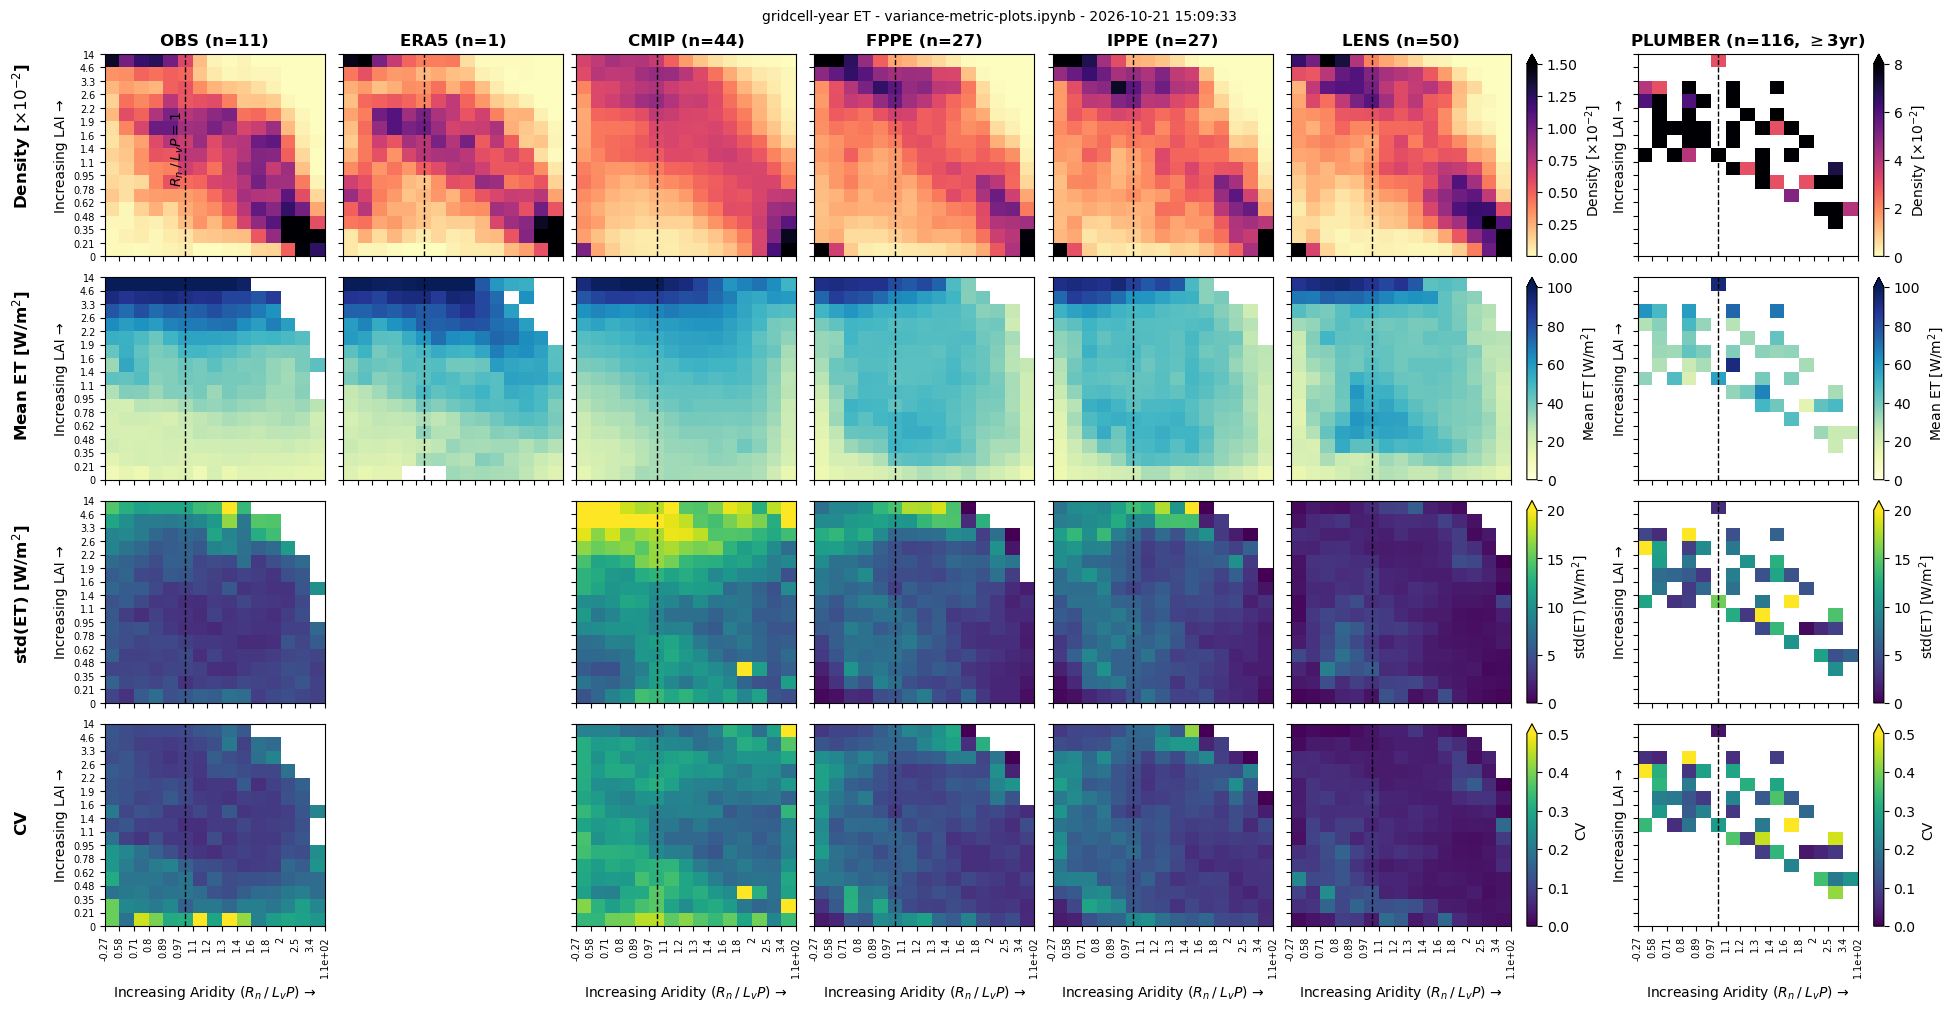

In [5]:
fig, axes = plt.subplots(4, len(FAMILIES), sharex=True, sharey=True, figsize=(19, 10), layout="constrained")
axs = axes.ravel()

vlims = [
    (0, 1.5),
    (0, 100),
    (0, 20),
    (0, 0.5),
]
cmaps = [
    "magma_r", "YlGnBu", "viridis", "viridis",
]
cv_thresh = 1.0
cv_hatch = "///"

plum_vlims = [
    (0, 8),
    vlims[1],
    vlims[2],
    vlims[3],
]


## GRIDDED PRODUCTS
row_labels = ["Density [$\\times10^{-2}$]", "Mean ET [W/m$^2$]", "std(ET) [W/m$^2$]", "CV"]
for i, (label, d) in enumerate(zip(row_labels, [rho_mem, mu_mem, sigma_mem, cv_mem])):
    for j, fam in enumerate(cfg.FAMILIES):
        if i == 0:
            di = (d[fam] * 1e2).where(~np.isnan(d[fam]))
        else:
            di = d[fam]

        mappable = di.plot(
            ax=axes[i, j],
            cmap=cmaps[i],
            vmin=vlims[i][0],
            vmax=vlims[i][1],
            add_labels=False,
            add_colorbar=False,
        )

        if i == 3:
            axes[i, j].pcolor(
                di.x_bin,
                di.y_bin,
                di.where(di > cv_thresh),
                facecolor="none", edgecolor="white", hatch=cv_hatch, linewidth=0,
            )

    cb = fig.colorbar(mappable, ax=axes[i, -2], label=label, pad=0.05, extend="max")
    if i == 3:
        cb.ax.axhline(cv_thresh, lw=2, c="white")
        cb.ax.axhspan(
            cv_thresh,
            vlims[i][1],
            facecolor="none", edgecolor="white",
            hatch=cv_hatch, linewidth=0,
        )
        


## PLUMBER
for i, (label, d) in enumerate(zip(
        row_labels,
        [
            pool_all["plumber"].sel(stats="count").where(pool_all["plumber"].sel(stats="count") > 0),
            pool_all["plumber"].sel(stats="mean"),
            np.sqrt(pool_all["plumber"].sel(stats="var_pop")),
            np.sqrt(pool_all["plumber"].sel(stats="var_pop")) / pool_all["plumber"].sel(stats="mean"),
            cv_mem["plumber"],
        ]
    )):
    mappable = d.et.plot(
        ax=axes[i, -1],
        cmap=cmaps[i],
        vmin=plum_vlims[i][0],
        vmax=plum_vlims[i][1],
        add_labels=False,
        add_colorbar=False,
        # cbar_kwargs={"label": label}
    )
    cb = fig.colorbar(mappable, ax=axes[i, -1], label=label, pad=0.05, extend="max")
    if i == 3:
        axes[i, -1].pcolor(
            d.et.x_bin,
            d.et.y_bin,
            d.et.isel(member=0).where(d.et.isel(member=0) > cv_thresh),
            facecolor="none", edgecolor="white", hatch=cv_hatch, linewidth=0,
        )
        cb.ax.axhline(cv_thresh, lw=2, c="white")
        cb.ax.axhspan(
            cv_thresh,
            plum_vlims[i][1],
            facecolor="none", edgecolor="white",
            hatch=cv_hatch, linewidth=0,
        )
    axes[i, -1].set_ylabel("Increasing LAI →")


## FORMATTING + LABELS
for i, label in enumerate(row_labels):
    for j, fam in enumerate(FAMILIES):
        set_edge_ticks(axes[i, j], pool_all[fam], "{:.2g}")

        budyko_one = pool_all[fam].x_bin.sel(x_bin_center=1, method="nearest")
        axes[i, j].axvline(budyko_one, ls="--", c="k", lw=1)
        if (i == 0) and (j == 0):
            axes[i, j].text(
                budyko_one - 0.5, cfg.N_YBINS / 2, "$R_n \\: / \\: L_v P = 1$",
                ha="center", va="center", rotation=90,
                color="k", fontsize=10
            )

        if (i == 0) and (fam != "plumber"):
            axes[i, j].set_title(f"{fam.upper()} (n={len(pool_all[fam].member):d})", fontsize=12, fontweight="bold")
        if (i == 0) and (fam == "plumber"):
            axes[i, j].set_title(f"{fam.upper()} (n={pool_all[fam].et.attrs['n_towers']:d}, $\\geq$3yr)", fontsize=12, fontweight="bold")
        if i == 3:
            axes[i, j].set_xlabel("Increasing Aridity ($R_n \\: / \\: L_v P$) →")
        if j == 0:
            axes[i, j].set_ylabel("Increasing LAI →")

fig.canvas.draw()
for i, label in enumerate(row_labels):
    row_center = axes[i, 0].get_position().y0 + axes[i, 0].get_position().height / 2
    fig.text(-0.015, row_center, label, va="center", ha="center", fontsize=12, fontweight="bold", rotation=90)

axes[2, 1].remove()
axes[3, 1].remove()

fout = qbin_dir(cfg.FIG_ROOT, "all") / f"all.et{'_clim' if ET_CLIM else ''}.{TAG}.density_summary.png"
finish(fig, fout)

## Constraint ratio plot

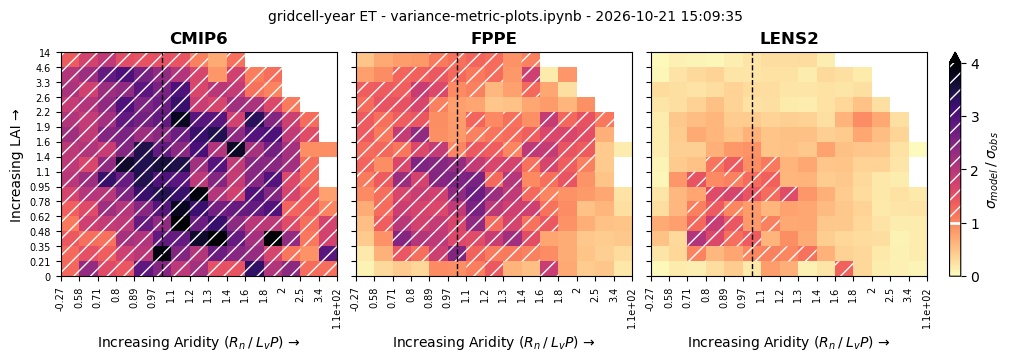

In [6]:
vmin = 0
vmax = 4
cmap = "magma_r"
r_obs_thresh = 1

fig, axs = plt.subplots(1, 3, figsize=(10, 3.5), sharex=True, sharey=True, layout="constrained")
r_cmip_obs.plot(ax=axs[0], cmap=cmap, vmin=vmin, vmax=vmax, add_colorbar=False, add_labels=False)
r_fppe_obs.plot(ax=axs[1], cmap=cmap, vmin=vmin, vmax=vmax, add_colorbar=False, add_labels=False)
mp = r_lens_obs.plot(ax=axs[2], cmap=cmap, vmin=vmin, vmax=vmax, add_colorbar=False, add_labels=False)

for ax, da, label in zip(axs, [r_cmip_obs, r_fppe_obs, r_lens_obs], ["CMIP6", "FPPE", "LENS2"]):
    mappable = da.plot(ax=ax, cmap=cmap, vmin=vmin, vmax=vmax, add_colorbar=False, add_labels=False)
    ax.pcolor(
        da.x_bin,
        da.y_bin,
        da.where(da > r_obs_thresh),
        facecolor="none", edgecolor="white", hatch="//", linewidth=0,
    )
    ax.axvline(da.x_bin.sel(x_bin_center=1, method="nearest"), ls="--", c="k", lw=1)
    set_edge_ticks(ax, da, "{:.2g}")
    ax.set_xlabel("Increasing Aridity ($R_n \\: / \\: L_v P$) →")
    ax.set_title(label, fontsize=12, fontweight="bold")

axs[0].set_ylabel("Increasing LAI →")

cb = fig.colorbar(mappable, ax=axs, label="$\\sigma_{model} \\: / \\: \\sigma_{obs}$", pad=0.02, extend="max")
cb.ax.axhline(r_obs_thresh, lw=2, c="white")
cb.ax.axhspan(
    r_obs_thresh,
    vmax,
    facecolor="none", edgecolor="white",
    hatch="//", linewidth=0,
)

fout = qbin_dir(cfg.FIG_ROOT, "all") / f"all.et{'_clim' if ET_CLIM else ''}.{TAG}.constrain_ratio.png"
finish(fig, fout)

## PLUMBER

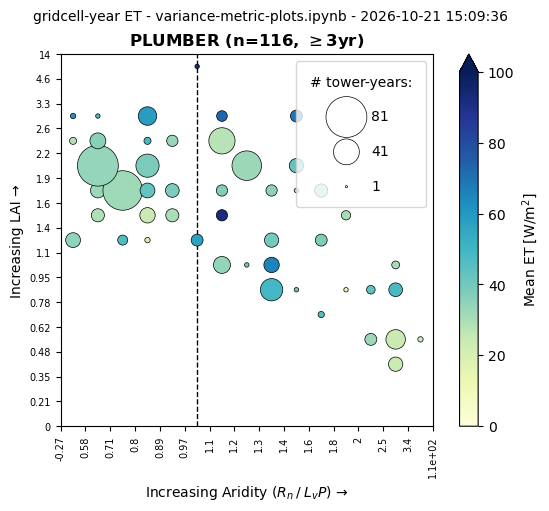

In [7]:
## PLUMBER binned ET as circles: color is the mean ET, radius is proportional to the number of samples
# in the bin (towers when ET_CLIM, tower-years otherwise); empty bins are not drawn
plum = pool_all["plumber"].et.isel(member=0)
plum_mean = plum.sel(stats="mean").values
plum_count = plum.sel(stats="count").values
y_idx, x_idx = np.nonzero((plum_count > 0) & np.isfinite(plum_mean))  # (y_bin, x_bin) of each non-empty bin

r_max = 150  # radius [pt] of the fullest bin (about half a bin width)
def radius_to_size(n):
    # scatter's s is the marker area [pt^2], so s = r^2 makes the radius proportional to n
    return ((r_max * n + 5) / plum_count.max()) ** 1.35

fig, ax = plt.subplots(figsize=(5.5, 5), layout="constrained")
sc = ax.scatter(
    x_idx, y_idx, s=radius_to_size(plum_count[y_idx, x_idx]), c=plum_mean[y_idx, x_idx],
    cmap="YlGnBu", vmin=0, vmax=100, edgecolor="k", linewidth=0.5, zorder=3,
)
fig.colorbar(sc, ax=ax, label="Mean ET [W/m$^2$]", extend="max", fraction=0.05)

# Size legend, in the empty high-LAI, arid corner
n_unit = "towers" if ET_CLIM else "tower-years"
n_ref = np.unique(np.linspace(1, plum_count.max(), 3).round().astype(int))[::-1]
handles = [ax.scatter([], [], s=radius_to_size(n), facecolor="none", edgecolor="k", linewidth=0.5) for n in n_ref]
ax.legend(handles, [f"{n:d}" for n in n_ref], title=f"# {n_unit}:", loc="upper right", labelspacing=1.5, borderpad=1, fontsize=10, frameon=True)

budyko_one = pool_all["plumber"].x_bin.sel(x_bin_center=1, method="nearest")
ax.axvline(budyko_one, ls="--", c="k", lw=1)
ax.set_xlim(-0.5, cfg.N_XBINS - 0.5)
ax.set_ylim(-0.5, cfg.N_YBINS - 0.5)
ax.set_aspect("equal")
set_edge_ticks(ax, plum, "{:.2g}")
ax.set_xticks(np.arange(-0.5, 15), minor=True)
ax.set_yticks(np.arange(-0.5, 15), minor=True)
ax.grid(which="minor", c="0.9", lw=0.5)
ax.tick_params(which="minor", length=0)
ax.set_xlabel("Increasing Aridity ($R_n \\: / \\: L_v P$) →")
ax.set_ylabel("Increasing LAI →")
ax.set_title(
    f"PLUMBER (n={pool_all['plumber'].et.attrs['n_towers']:d}, $\\geq$3yr)",
    fontsize=12, fontweight="bold",
)

fout = qbin_dir(cfg.FIG_ROOT, "plumber") / f"plumber.et{'_clim' if ET_CLIM else ''}.{TAG}.mean_circles.png"
finish(fig, fout)

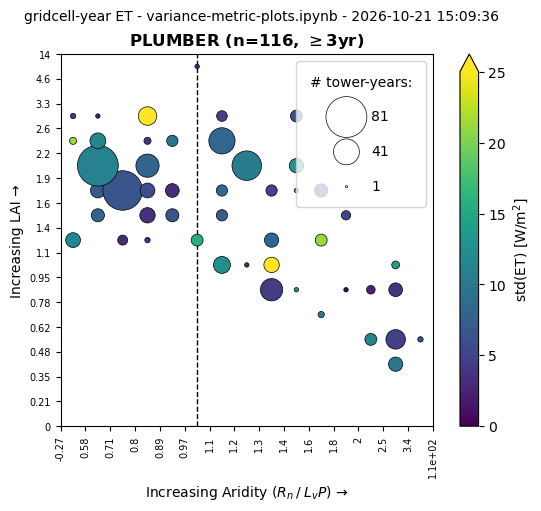

In [8]:
## PLUMBER binned ET as circles: color is the mean ET, radius is proportional to the number of samples
# in the bin (towers when ET_CLIM, tower-years otherwise); empty bins are not drawn
plum = pool_all["plumber"].et.isel(member=0)
plum_std = np.sqrt(plum.sel(stats="var_pop").values)
plum_count = plum.sel(stats="count").values
y_idx, x_idx = np.nonzero((plum_count > 0) & np.isfinite(plum_std))  # (y_bin, x_bin) of each non-empty bin
single_sample = plum_count[y_idx, x_idx] == 1
sample_counts = plum_count[y_idx, x_idx]
sample_values = plum_std[y_idx, x_idx]

r_max = 150  # radius [pt] of the fullest bin (about half a bin width)
def radius_to_size(n):
    # scatter's s is the marker area [pt^2], so s = r^2 makes the radius proportional to n
    return ((r_max * n + 5) / plum_count.max()) ** 1.35

fig, ax = plt.subplots(figsize=(5.5, 5), layout="constrained")
sc = ax.scatter(
    x_idx[~single_sample], y_idx[~single_sample],
    s=radius_to_size(sample_counts[~single_sample]), c=sample_values[~single_sample],
    cmap="viridis", vmin=0, vmax=25, edgecolor="k", linewidth=0.5, zorder=3,
)
ax.scatter(
    x_idx[single_sample], y_idx[single_sample], s=radius_to_size(sample_counts[single_sample]),
    facecolor="white", edgecolor="k", linewidth=0.5, zorder=3,
)
fig.colorbar(sc, ax=ax, label="std(ET) [W/m$^2$]", extend="max", fraction=0.05)

# Size legend, in the empty high-LAI, arid corner
n_unit = "towers" if ET_CLIM else "tower-years"
n_ref = np.unique(np.linspace(1, plum_count.max(), 3).round().astype(int))[::-1]
handles = [ax.scatter([], [], s=radius_to_size(n), facecolor="none", edgecolor="k", linewidth=0.5) for n in n_ref]
ax.legend(handles, [f"{n:d}" for n in n_ref], title=f"# {n_unit}:", loc="upper right", labelspacing=1.5, borderpad=1, fontsize=10, frameon=True)

budyko_one = pool_all["plumber"].x_bin.sel(x_bin_center=1, method="nearest")
ax.axvline(budyko_one, ls="--", c="k", lw=1)
ax.set_xlim(-0.5, cfg.N_XBINS - 0.5)
ax.set_ylim(-0.5, cfg.N_YBINS - 0.5)
ax.set_aspect("equal")
set_edge_ticks(ax, plum, "{:.2g}")
ax.set_xticks(np.arange(-0.5, 15), minor=True)
ax.set_yticks(np.arange(-0.5, 15), minor=True)
ax.grid(which="minor", c="0.9", lw=0.5)
ax.tick_params(which="minor", length=0)
ax.set_xlabel("Increasing Aridity ($R_n \\: / \\: L_v P$) →")
ax.set_ylabel("Increasing LAI →")
ax.set_title(
    f"PLUMBER (n={pool_all['plumber'].et.attrs['n_towers']:d}, $\\geq$3yr)",
    fontsize=12, fontweight="bold",
)

fout = qbin_dir(cfg.FIG_ROOT, "plumber") / f"plumber.et{'_clim' if ET_CLIM else ''}.{TAG}.sigma_circles.png"
finish(fig, fout)

## Land area

### CMIP6

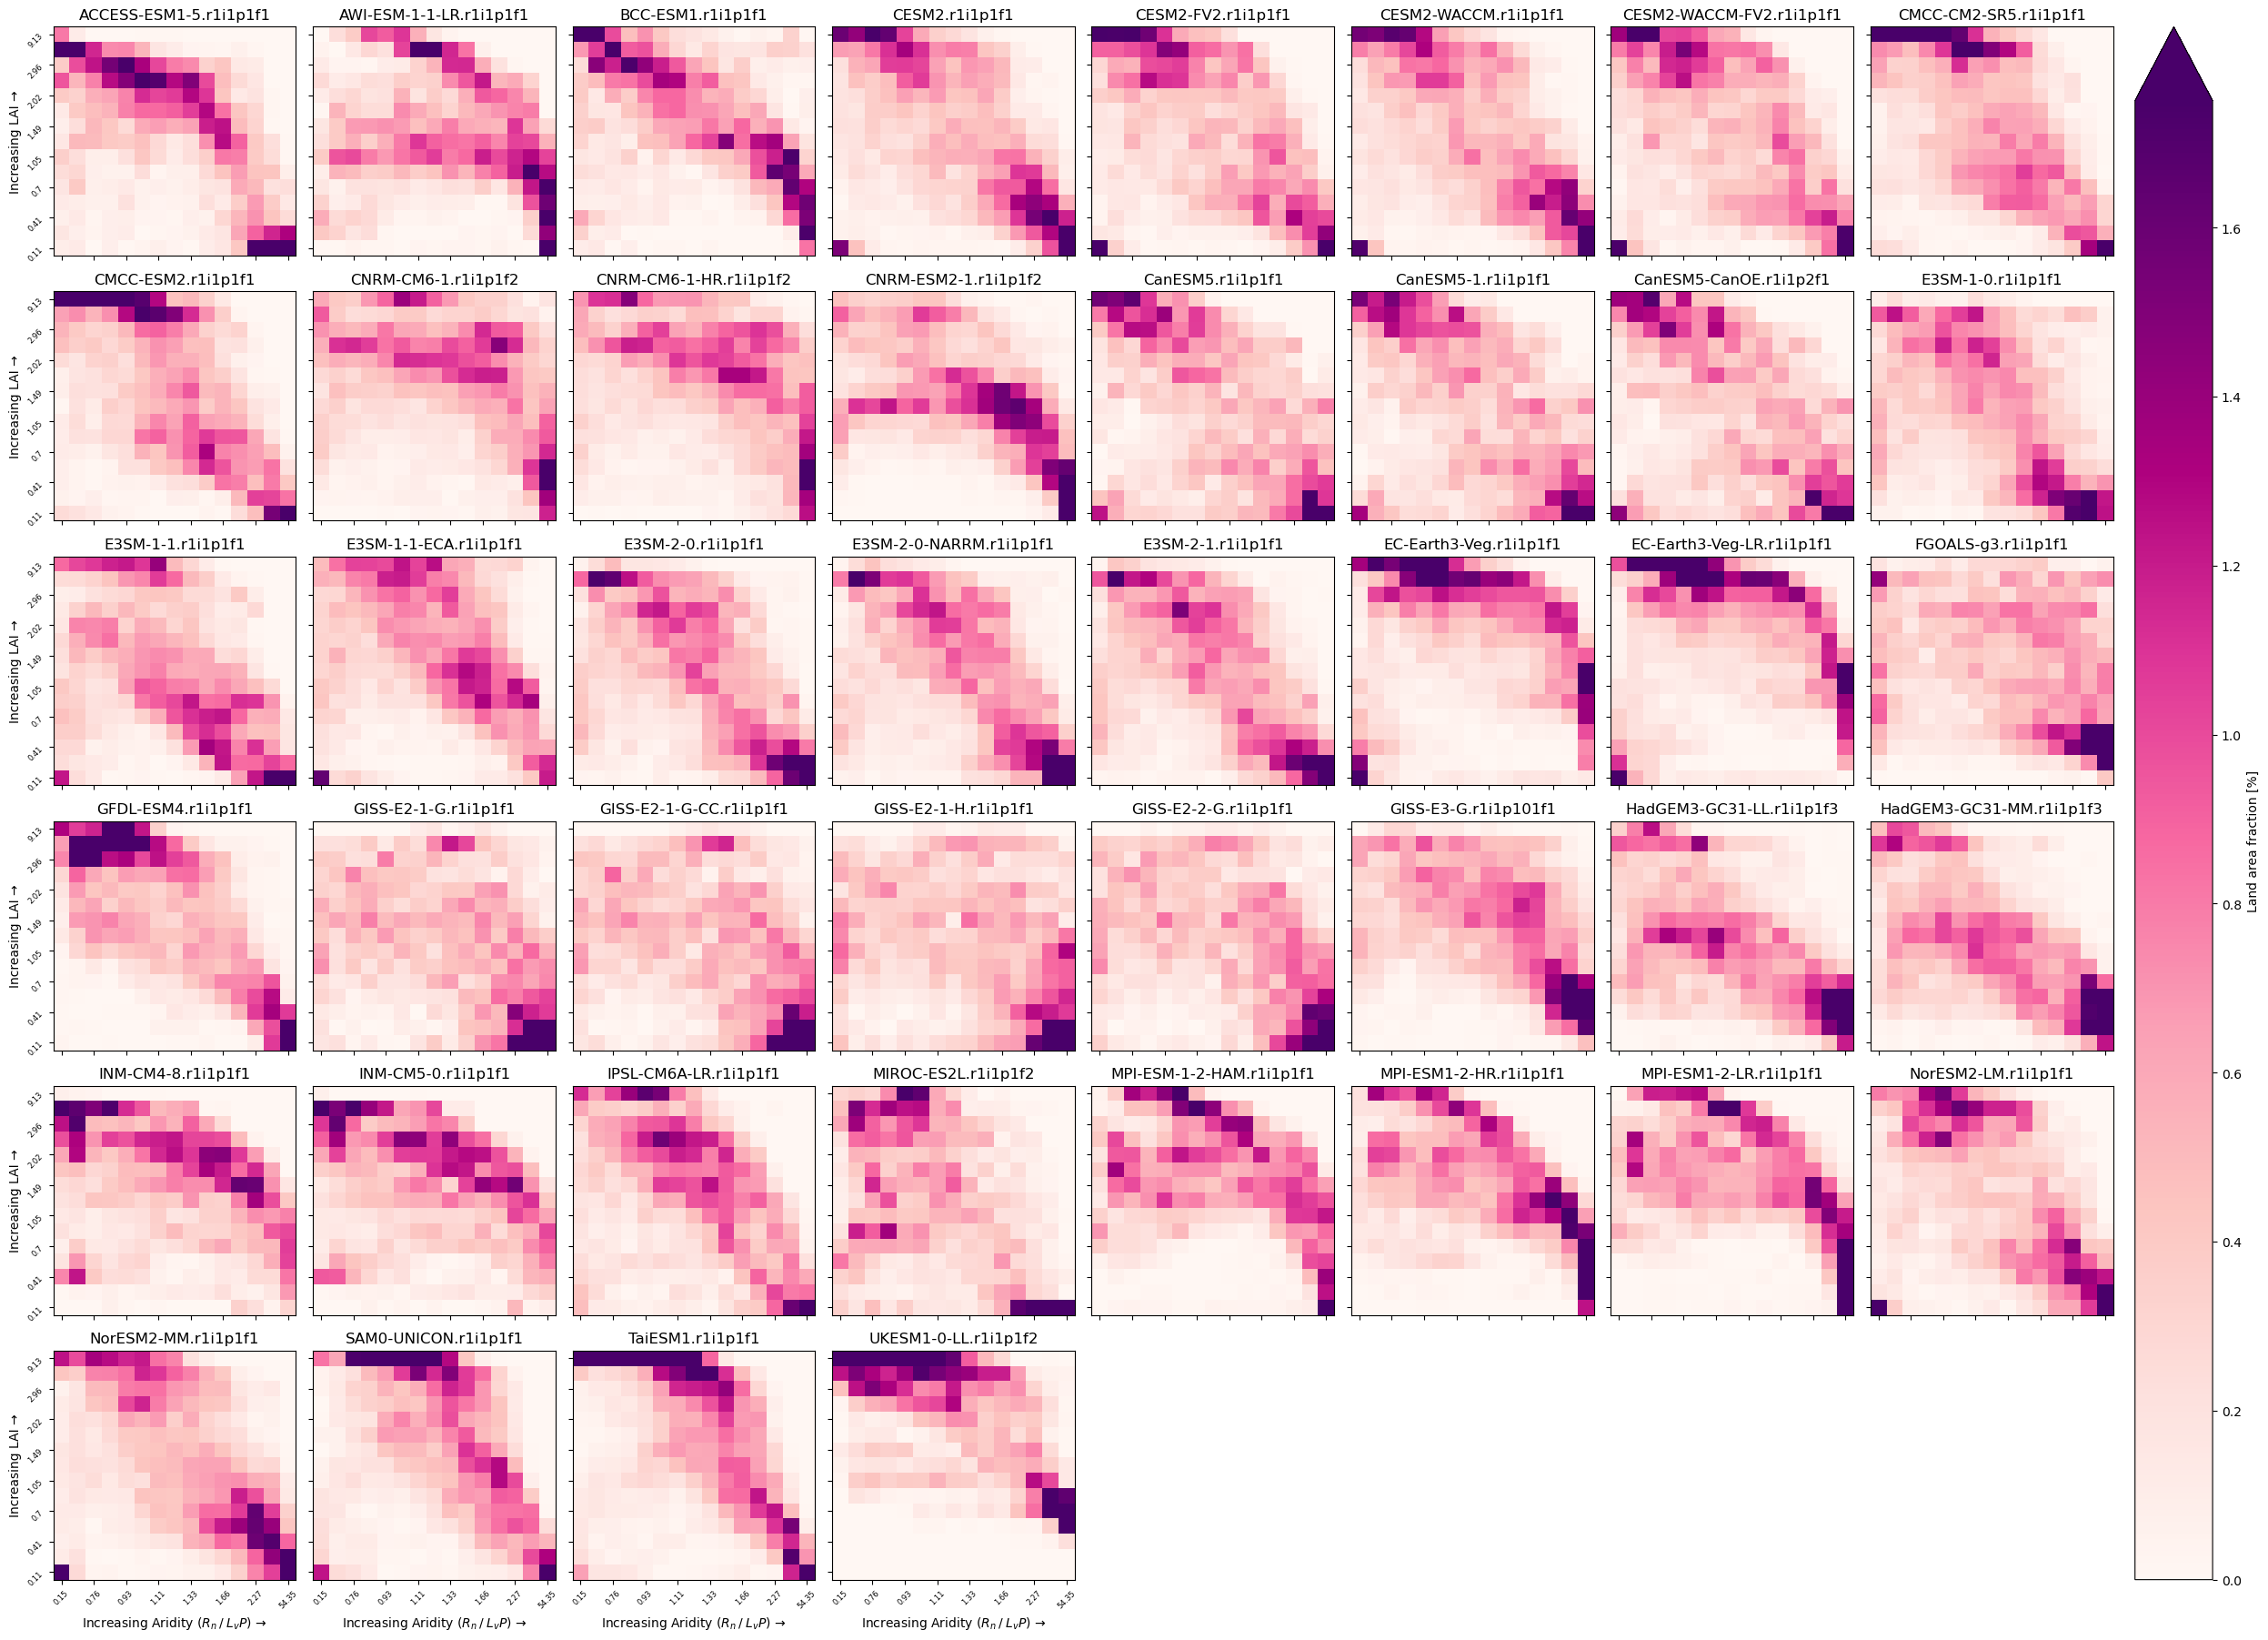

In [9]:
fam = "cmip"

fg = (la_mem[fam].land_area_frac * 100).plot(
    col="member", col_wrap=8,
    robust=True, cmap="RdPu",
    cbar_kwargs={"fraction": 0.05, "pad": 0.01, "label": "Land area fraction [%]"},
    
)

for ax, m in zip(fg.axs.ravel(), la_mem[fam].member):
    ax.set_title(m.item())
    ax.set_xticks(np.arange(0, 15, 2))
    ax.set_yticks(np.arange(0, 15, 2))
    ax.set_xticklabels(np.round(la_mem[fam].x_bin_center.values, 2)[::2], fontsize=6, rotation=45)
    ax.set_yticklabels(np.round(la_mem[fam].y_bin_center.values, 2)[::2], fontsize=6, rotation=45)

for ax in fg.axs[-1]:
    ax.set_xlabel("Increasing Aridity ($R_n \\: / \\: L_v P$) →")

for ax in fg.axs[:, 0]:
    ax.set_ylabel("Increasing LAI →")

# fout = qbin_dir(cfg.FIG_ROOT, "all") / f"all.et{'_clim' if ET_CLIM else ''}.{TAG}.constrain_ratio.png"
# finish(fig, fout)

### FPPE

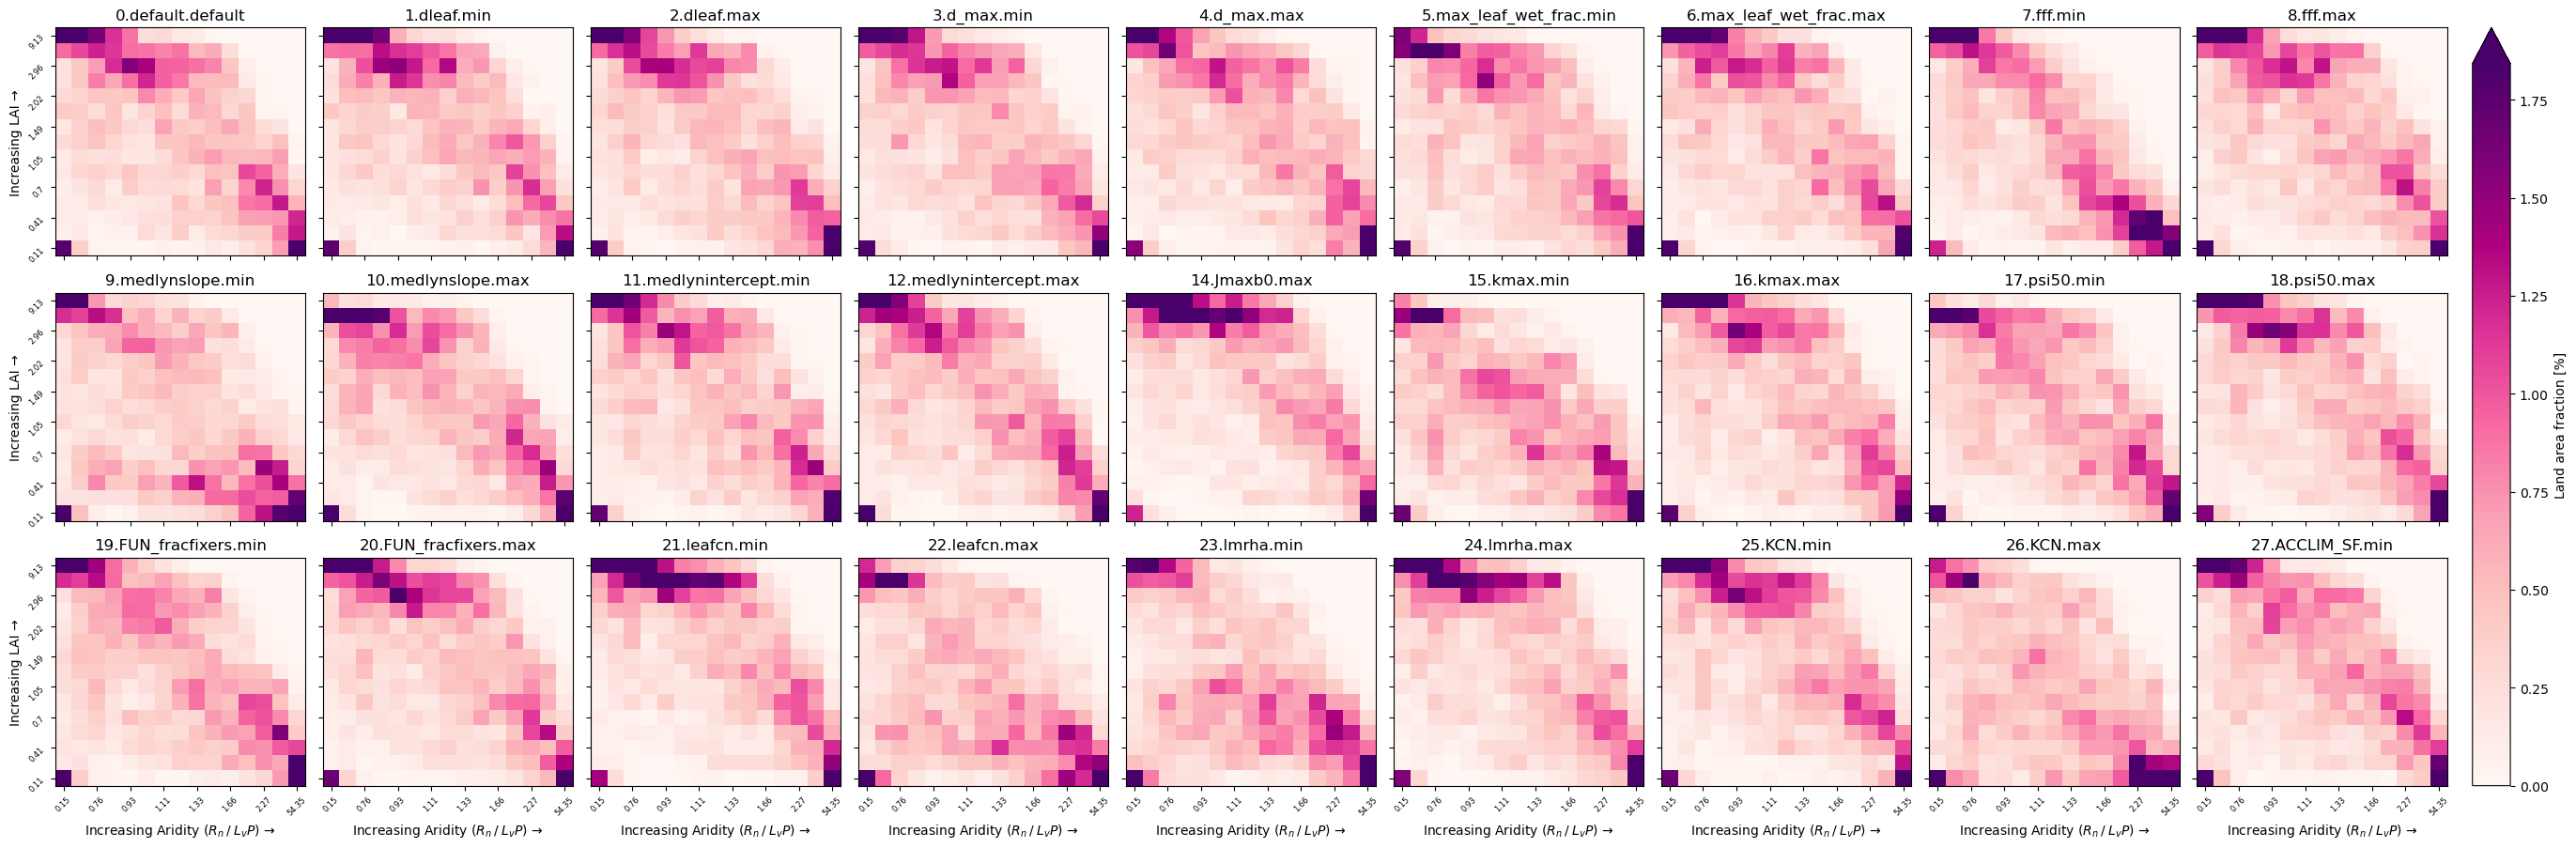

In [10]:
fam = "fppe"
ncol = 9

fg = (la_mem[fam].land_area_frac * 100).plot(
    col="member", col_wrap=ncol,
    robust=True, cmap="RdPu",
    cbar_kwargs={"fraction": 0.05, "pad": 0.01, "label": "Land area fraction [%]"},
    
)

for ax, m in zip(fg.axs.ravel(), la_mem[fam].member):
    ax.set_title(m.item())
    ax.set_xticks(np.arange(0, 15, 2))
    ax.set_yticks(np.arange(0, 15, 2))
    ax.set_xticklabels(np.round(la_mem[fam].x_bin_center.values, 2)[::2], fontsize=6, rotation=45)
    ax.set_yticklabels(np.round(la_mem[fam].y_bin_center.values, 2)[::2], fontsize=6, rotation=45)

for ax in fg.axs[-1]:
    ax.set_xlabel("Increasing Aridity ($R_n \\: / \\: L_v P$) →")

for ax in fg.axs[:, 0]:
    ax.set_ylabel("Increasing LAI →")

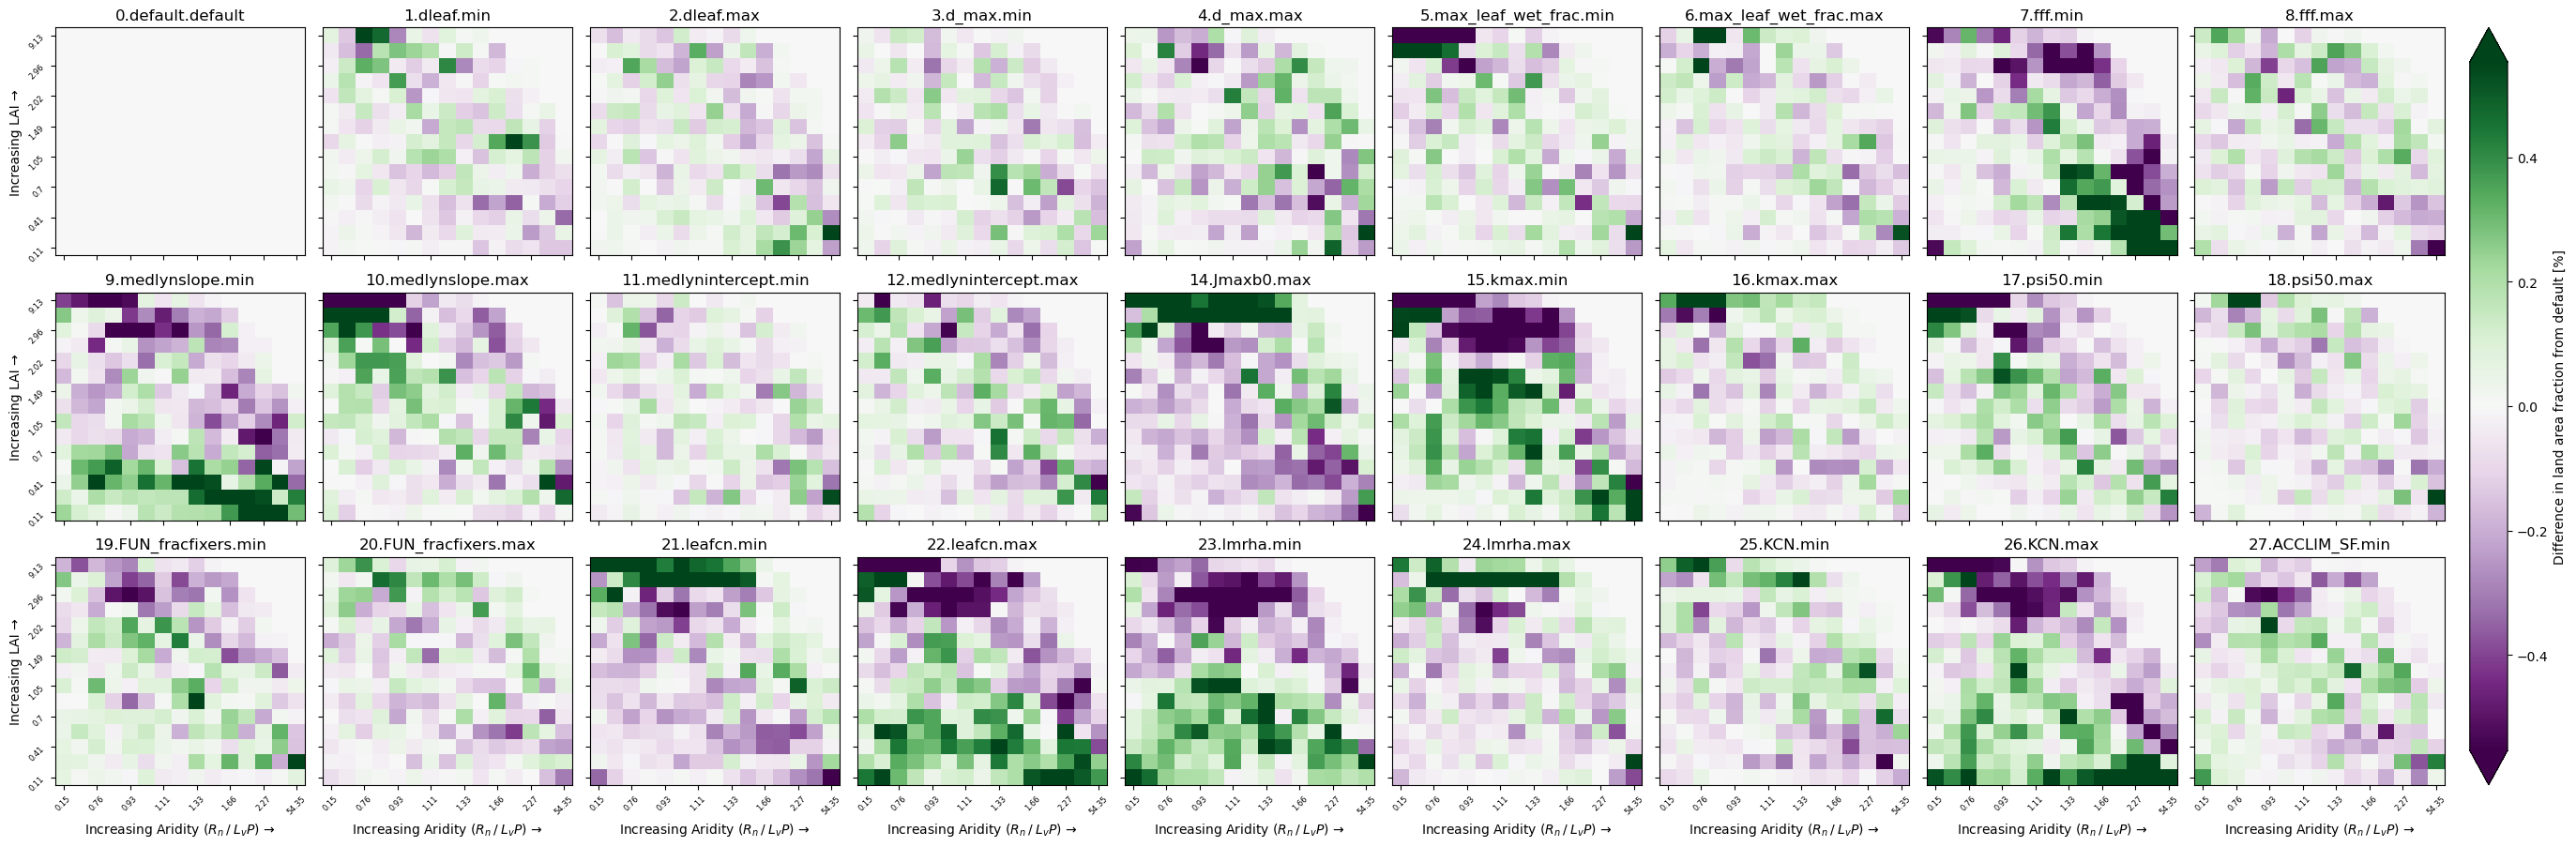

In [11]:
fam = "fppe"
ncol = 9

x = (la_mem[fam].land_area_frac - la_mem[fam].land_area_frac.isel(member=0)) * 100

fg = x.plot(
    col="member", col_wrap=ncol,
    robust=True, cmap="PRGn",
    cbar_kwargs={"fraction": 0.05, "pad": 0.01, "label": "Difference in land area fraction from default [%]"},
    
)

for ax, m in zip(fg.axs.ravel(), la_mem[fam].member):
    ax.set_title(m.item())
    ax.set_xticks(np.arange(0, 15, 2))
    ax.set_yticks(np.arange(0, 15, 2))
    ax.set_xticklabels(np.round(la_mem[fam].x_bin_center.values, 2)[::2], fontsize=6, rotation=45)
    ax.set_yticklabels(np.round(la_mem[fam].y_bin_center.values, 2)[::2], fontsize=6, rotation=45)

for ax in fg.axs[-1]:
    ax.set_xlabel("Increasing Aridity ($R_n \\: / \\: L_v P$) →")

for ax in fg.axs[:, 0]:
    ax.set_ylabel("Increasing LAI →")

### LENS2

### OBS

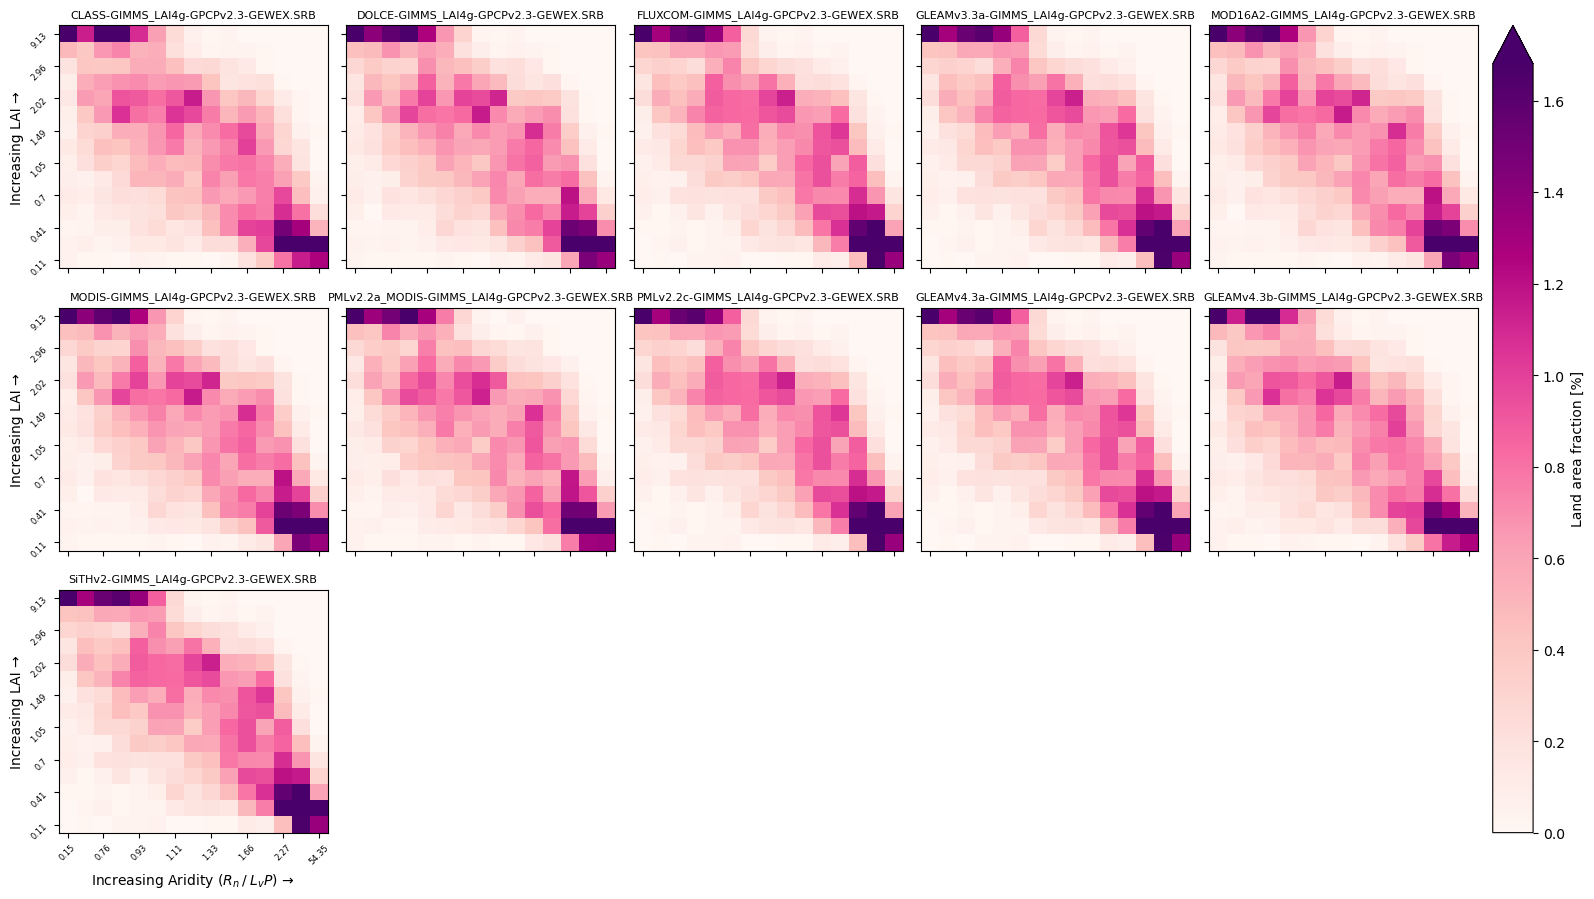

In [12]:
fam = "obs"
ncol = 5

fg = (la_mem[fam].land_area_frac * 100).plot(
    col="member", col_wrap=ncol,
    robust=True, cmap="RdPu",
    cbar_kwargs={"fraction": 0.05, "pad": 0.01, "label": "Land area fraction [%]"},
    
)

for ax, m in zip(fg.axs.ravel(), la_mem[fam].member):
    ax.set_title(m.item(), fontsize=8)
    ax.set_xticks(np.arange(0, 15, 2))
    ax.set_yticks(np.arange(0, 15, 2))
    ax.set_xticklabels(np.round(la_mem[fam].x_bin_center.values, 2)[::2], fontsize=6, rotation=45)
    ax.set_yticklabels(np.round(la_mem[fam].y_bin_center.values, 2)[::2], fontsize=6, rotation=45)

for ax in fg.axs[-1]:
    ax.set_xlabel("Increasing Aridity ($R_n \\: / \\: L_v P$) →")

for ax in fg.axs[:, 0]:
    ax.set_ylabel("Increasing LAI →")

### Summary of `std(lf)`

In [13]:
cfg.FAMILIES

('obs', 'era5', 'cmip', 'fppe', 'ippe', 'lens')

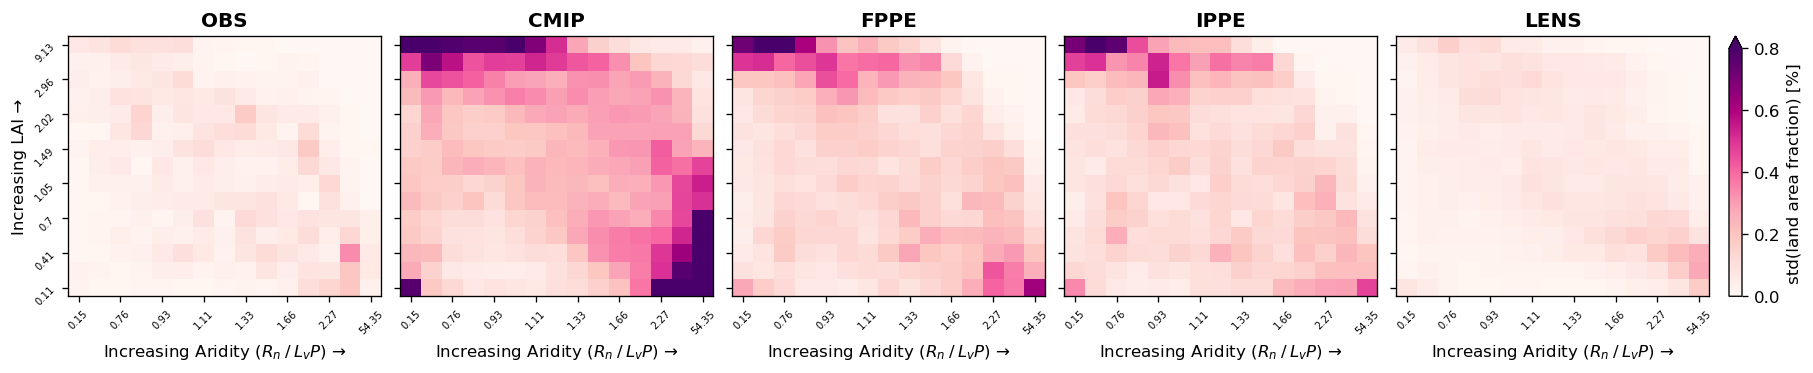

In [14]:
families = ('obs', 'cmip', 'fppe', 'ippe', 'lens')

fig, axs = plt.subplots(1, len(families), figsize=(15, 3), layout="constrained", sharex=True, sharey=True, dpi=120)

for ax, fam in zip(axs, families):
    mappable = (la_mem[fam].land_area_frac * 100).std(dim="member").plot(
        ax=ax, cmap="RdPu", vmin=0, vmax=0.8,
        add_labels=False, add_colorbar=False
    )
    ax.set_title(fam.upper(), fontweight="bold")
    ax.set_xticks(np.arange(0, 15, 2))
    ax.set_yticks(np.arange(0, 15, 2))
    ax.set_xticklabels(np.round(la_mem[fam].x_bin_center.values, 2)[::2], fontsize=6, rotation=45)
    ax.set_yticklabels(np.round(la_mem[fam].y_bin_center.values, 2)[::2], fontsize=6, rotation=45)
    ax.set_xlabel("Increasing Aridity ($R_n \\: / \\: L_v P$) →")

axs[0].set_ylabel("Increasing LAI →")
cb = fig.colorbar(mappable, ax=axs, label="std(land area fraction) [%]", pad=0.01, extend="max")

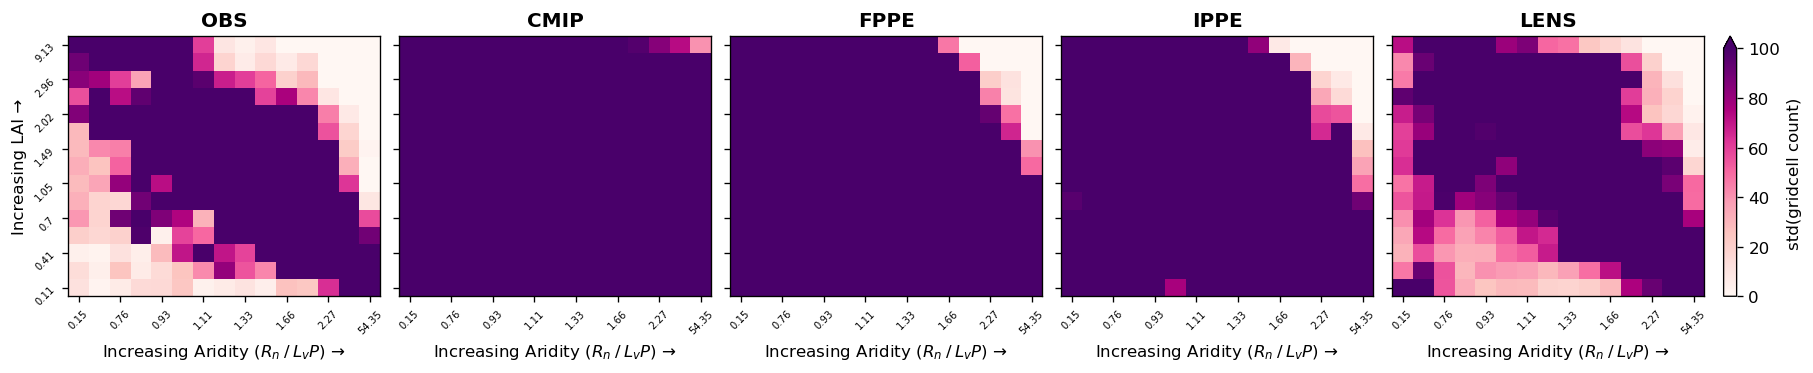

In [15]:
families = ('obs', 'cmip', 'fppe', 'ippe', 'lens')

fig, axs = plt.subplots(1, len(families), figsize=(15, 3), layout="constrained", sharex=True, sharey=True, dpi=120)

for ax, fam in zip(axs, families):
    mappable = pool_all[fam].et.sel(stats="count").std(dim="member").plot(
        ax=ax, cmap="RdPu", vmin=0, vmax=100,
        add_labels=False, add_colorbar=False
    )
    ax.set_title(fam.upper(), fontweight="bold")
    ax.set_xticks(np.arange(0, 15, 2))
    ax.set_yticks(np.arange(0, 15, 2))
    ax.set_xticklabels(np.round(rho_mem[fam].x_bin_center.values, 2)[::2], fontsize=6, rotation=45)
    ax.set_yticklabels(np.round(rho_mem[fam].y_bin_center.values, 2)[::2], fontsize=6, rotation=45)
    ax.set_xlabel("Increasing Aridity ($R_n \\: / \\: L_v P$) →")

axs[0].set_ylabel("Increasing LAI →")
cb = fig.colorbar(mappable, ax=axs, label="std(gridcell count)", pad=0.01, extend="max")

In [16]:
gm_et = {}

for fam in cfg.FAMILIES:
    lf = la_mem[fam].land_area_frac
    et = pool_all[fam].et.sel(stats="mean")

    gm_et[fam] = (lf * et).sum(dim=["x_bin", "y_bin"])

    print(fam.upper())
    print(f"ens mean: {gm_et[fam].mean():0.3f}")
    print(f"ens max: {gm_et[fam].max():0.3f}")
    print(f"ens min: {gm_et[fam].min():0.3f}")
    print(f"ens std: {gm_et[fam].std():0.3f}")

OBS
ens mean: 44.908
ens max: 52.228
ens min: 39.952
ens std: 3.829
ERA5
ens mean: 50.649
ens max: 50.649
ens min: 50.649
ens std: 0.000
CMIP
ens mean: 49.187
ens max: 66.130
ens min: 34.951
ens std: 5.581
FPPE
ens mean: 46.575
ens max: 49.806
ens min: 41.591
ens std: 2.346
IPPE
ens mean: 46.702
ens max: 50.654
ens min: 41.443
ens std: 2.638
LENS
ens mean: 44.966
ens max: 45.303
ens min: 44.690
ens std: 0.134
